# Сборка комплексов из двух Cas-белков на ДНК

Модуль собирает модель, где **два Cas-белка сидят на одной молекуле ДНК** на заданном
расстоянии между PAM-сайтами, и меряет геометрию получившейся пары.

Основной вопрос, на который он отвечает: на каком расстоянии окажутся функциональные концы
двух белков при разном разносе сайтов посадки. Это нужно, когда между двумя Cas должно
что-то произойти — сшивка доменов, сближение концов гРНК, работа линкера.

**Что меряется:**

| параметр | что это |
|---|---|
| `"3'"` | между 3'-концами двух гРНК |
| `'C'` | между C-концами белков |
| `'N'` | между N-концами белков |

Плюс проверка на столкновение белков друг с другом.

Ноутбук запускается сверху вниз и ничего не требует кроме окружения и ансамблей
конформеров ДНК — структуру Cas он скачает сам. Весь прогон занимает пару минут.

## Перед запуском

Нужно две вещи, обе описаны в [README](README.md):

1. **Окружение** из `requirements.txt` на Python 3.12, и ядро этого ноутбука — его
   интерпретатор. В VS Code и в Jupyter ядро выбирается в правом верхнем углу: нужен
   питон из `.venv` этого репозитория (или ядро, которое вы под него зарегистрировали).
2. **Ансамбли конформеров линкерной ДНК** — папки `pdb_files_40/` и `pdb_files_100/`
   рядом с `cas_complex.py`. Они лежат в релизе двумя архивами: без них сборка
   не заработает, потому что линкер между белками вырезается именно из них.

Следующие две ячейки это проверяют: импортируют модуль и печатают, что нашлось.

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')   # MDAnalysis шумит предупреждениями про CRYST1

import nglview as nv
import numpy as np

from cas_complex import *

%matplotlib inline

In [2]:
from importlib.metadata import version

print('python     ', sys.version.split()[0])
for package in ('numpy', 'scipy', 'matplotlib', 'MDAnalysis', 'nglview', 'pypdb', 'tqdm'):
    print(f'{package:11}', version(package))

for n_bp, folder in DNA_LIBRARIES.items():
    path = os.path.join(MODULE_DIR, folder)
    found = len(os.listdir(path)) if os.path.isdir(path) else 0
    print(f'ансамбль {n_bp} п.н.:', f'{found} конформеров' if found
          else f'НЕ НАЙДЕН - распакуйте {folder} рядом с cas_complex.py, см. README')

python      3.12.15
numpy       2.5.3
scipy       1.18.1
matplotlib  3.11.2
MDAnalysis  2.10.0
nglview     4.0.1
pypdb       2.11
tqdm        4.70.1
ансамбль 40 п.н.: 10000 конформеров
ансамбль 100 п.н.: 10000 конформеров


## Структура Cas-белка

Структуру можно задать двумя способами: **четырёхсимвольным PDB ID** — тогда модуль
скачает её из RCSB сам, — либо **путём к локальному файлу** в формате PDB.

В примерах ниже используется SpCas9 (PDB ID 5Y36). Структура читается заново при каждой
сборке, а сборок дальше будет много, поэтому скачаем её один раз в файл и будем передавать
путь: с PDB ID модуль обращался бы к RCSB на каждую сборку.

In [3]:
import urllib.request

os.makedirs('PDB', exist_ok=True)
if not os.path.exists('PDB/5Y36.pdb'):
    urllib.request.urlretrieve('https://files.rcsb.org/download/5Y36.pdb', 'PDB/5Y36.pdb')

print('структура на месте:', os.path.getsize('PDB/5Y36.pdb') // 1024, 'КБ')

структура на месте: 1233 КБ


## Быстрый старт

`build_models` принимает: названия двух белков, их структуры, ориентацию, список разносов
PAM-PAM и флаг сохранения. Возвращает словарь `разнос -> модель`.

In [4]:
model = build_models('SpCas9', 'SpCas9', 'PDB/5Y36.pdb', 'PDB/5Y36.pdb',
                     2, [60], 0)

model[60]

<Universe with 29352 atoms>

### Ориентации

| число | ориентация | что значит |
|---|---|---|
| `0` | PAM-direct | оба PAM смотрят в одну сторону |
| `1` | PAM-in | PAM-сайты обращены друг к другу |
| `2` | PAM-out | PAM-сайты смотрят наружу |

### Допустимые разносы

Минимум задаётся геометрией самих структур, максимум — длиной ДНК в библиотеке.
Если выйти за границы, функция печатает сообщение и возвращает `None`.

In [5]:
Cas1, Cas2 = prepare_structures('SpCas9', 'SpCas9', 'PDB/5Y36.pdb', 'PDB/5Y36.pdb', 'PAM-in')

C_resnums = Cas1.select_atoms('segid C').residues.resnums
limits = {'PAM-in': 0,
          'PAM-direct': abs(min(C_resnums) + 1),
          'PAM-out': abs(min(C_resnums + 1) + min(Cas2.select_atoms('segid C').residues.resnums + 1))}

for name, low in limits.items():
    print(f'{name:12} от {low:>3} до {MAX_PAM_PAM_DIST + low}')

PAM-in       от   0 до 97
PAM-direct   от  21 до 118
PAM-out      от  42 до 139


## Как посмотреть на модель

`nglview` рисует собранный комплекс в 3D прямо в ноутбуке: мышью крутится, колесом
масштабируется, по атому можно щёлкнуть и увидеть, что это за остаток.

Виджет живой только в запущенном ноутбуке. В статическом просмотре — например, на GitHub —
на его месте будет пусто: запустите ячейку у себя, и модель появится.

In [6]:
nv.show_mdanalysis(model[60].select_atoms('protein or nucleic'))

Так все цепи выглядят одинаково, и разобрать, где какой Cas, трудно. Удобнее раскрасить
по цепям — белки лентой, гРНК и ДНК трубкой. Цвета взяты те же, что на рисунках:
белки двух Cas сиреневый и бирюзовый, гРНК розовая, таргетная цепь ДНК тёмно-серая,
нетаргетная (та, что несёт оба PAM-сайта) — светло-серая.

In [7]:
view = nv.show_mdanalysis(model[60].select_atoms('segid A'), default_representation=False)
view.add_cartoon(color='#A894D4')                      # белок первого Cas

chains = [('segid a', 'cartoon', '#7FC4B8'),           # белок второго Cas
          ('segid B or segid b', 'tube', '#D94D73'),   # гРНК обоих
          ('segid C', 'tube', '#404040'),              # таргетная цепь ДНК
          ('segid D', 'tube', '#8C8C8C')]              # нетаргетная, с PAM-сайтами

for selection, style, colour in chains:
    component = view.add_trajectory(nv.MDAnalysisTrajectory(model[60].select_atoms(selection)))
    component.clear_representations()
    getattr(component, f'add_{style}')(color=colour)

view.center()
view

Отсюда же удобно:

- посмотреть на один Cas отдельно — `nv.show_mdanalysis(model[60].select_atoms('segid A or segid B'))`;
- увидеть измеряемое расстояние прямо на модели — `show_dist`, про него ниже;
- сохранить картинку: кнопка фотоаппарата в правом верхнем углу виджета или
  `view.download_image('комплекс.png')`;
- открыть модель во внешнем вьюере (ChimeraX, PyMOL) — сохранить её в PDB,
  см. раздел «Сохранение моделей».

## Проверка собранной модели

`check_model` печатает всё, что может быть не так: состав цепей, связность остова,
пропуски в нумерации, спаривание цепей. Если видите разрыв на картинке, а тут чисто —
перезагрузите ядро, скорее всего в памяти старый код.

In [8]:
check_model(model[60])

ЦЕПИ:
   segid A:  1368 ост. белок  chainID ['A']
   segid B:    99 ост. НК     chainID ['B']
   segid C:    68 ост. НК     chainID ['C']
   segid D:    68 ост. НК     chainID ['D']
   segid a:  1368 ост. белок  chainID ['a']
   segid b:    99 ост. НК     chainID ['b']

ОСТОВ НУКЛЕИНОВЫХ КИСЛОТ:
   chainID B:   99 ост., resnum -22..76, разрывов 0, пропусков нумерации 0
   chainID C:   68 ост., resnum -64..3, разрывов 0, пропусков нумерации 0
   chainID D:   68 ост., resnum 3..-64, разрывов 0, пропусков нумерации 0
   chainID b:   99 ост., resnum -22..76, разрывов 0, пропусков нумерации 0

СПАРИВАНИЕ ЦЕПЕЙ C и D (C1'-C1', спаренная пара ~10.5 A):
   спарено: 28 позиций
   расходятся: 40 позиций [-60, -59, -58, -57, -56, -55, -54, -53, -52, -51, -50, -49, -48, -47, -46, -45, -44, -43, -42, -41, -20, -19, -18, -17, -16, -15, -14, -13, -12, -11]
   расхождение на отрицательных номерах - это R-петля, так и должно быть:
   там таргетная цепь спарена с гРНК, а нетаргетная вытеснена

ИТОГ: про

[]

Цепи в собранной модели называются так:

| цепь | что это |
|---|---|
| `A`, `a` | белок первого и второго Cas |
| `B`, `b` | гРНК первого и второго Cas |
| `C` | таргетная цепь ДНК |
| `D` | нетаргетная цепь, несущая PAM |

Отдельные проверки, если нужны по одной:

In [9]:
print('столкновение белков:      ', check_clashing(model[60]))
print('атомов в зоне контакта:   ', how_many_atoms_clashing(model[60]))
print('связи остова O3-P, A:     ', round(min_backbone_bond(model[60]), 2),
      '..', round(max_backbone_gap(model[60]), 2))
print('швы разошлись:            ', check_seams(model[60]))

столкновение белков:       False
атомов в зоне контакта:    0
связи остова O3-P, A:      1.58 .. 1.61
швы разошлись:             False


## Расстояния

`get_dist` принимает список или словарь моделей и возвращает список расстояний.

In [10]:
models = build_models('SpCas9', 'SpCas9', 'PDB/5Y36.pdb', 'PDB/5Y36.pdb',
                      2, [50, 60, 70], 0)

for param in ("3'", 'C', 'N'):
    print(param, [round(x, 1) for x in get_dist(models, param)])

3' [np.float64(73.1), np.float64(120.0), np.float64(120.0)]
C [np.float64(116.7), np.float64(205.8), np.float64(199.6)]
N [np.float64(47.7), np.float64(97.1), np.float64(108.2)]


### Важно: расстояние меряется по прямой

Прямая между концами **может идти насквозь через ДНК или через белок**. Тогда число
ничего не говорит о том, достанет ли реальный линкер — ему пришлось бы идти в обход.

`check_dist_path` проверяет, свободен ли путь.

In [11]:
for d in (50, 60, 70):
    info = check_dist_path(models[d], "3'")
    status = f"перекрыто цепями {','.join(info['blocked_by'])}" if info['blocked'] else 'свободно'
    print(f"разнос {d}: {info['distance']:6.1f} A, зазор {info['clearance']:4.1f} A -> {status}")

разнос 50:   73.1 A, зазор  6.3 A -> свободно
разнос 60:  120.0 A, зазор  6.3 A -> свободно
разнос 70:  120.0 A, зазор  6.3 A -> свободно


### Показать расстояние на модели

`show_dist` рисует измеряемое расстояние прямо в nglview: цилиндр между концами и подпись.
**Зелёный** — прямая идёт свободно, **красный** — упирается в структуру.

In [12]:
show_dist(models[60], "3'")

## Статистика и графики

Конформер линкерной ДНК вытягивается случайно, поэтому на одном разносе получается не одно
число, а разброс. `plot_dist` собирает статистику по диапазону и строит график.

**Сверху** — на каждом разносе свой box-plot по сборкам **без столкновений**: прямоугольник
от первого до третьего квартиля, усы до минимума и максимума, маркер на медиане. Там, где
бесстолкновительных сборок нет совсем, не рисуется ничего: разнос недостижим.
**Снизу** — какая доля сборок столкнулась.

Закрашенный маркер — прямая свободна, полый — перекрыта.

/Users/ler0_oy/Claude/Module_dCas9/.venv/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/ler0_oy/Claude/Module_dCas9/.venv/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/ler0_oy/Claude/Module_dCas9/.venv/lib/python3.12/site-packages/MDAnalysis/core/universe.py:939: UserWarning: Reader has no dt information, set to 1.0 ps
  dt=self.trajectory.ts.dt * step,
/Users/ler0_oy/Claude/Module_dCas9/.venv/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/ler0_oy/Claude/Module_dCas9/.venv/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 

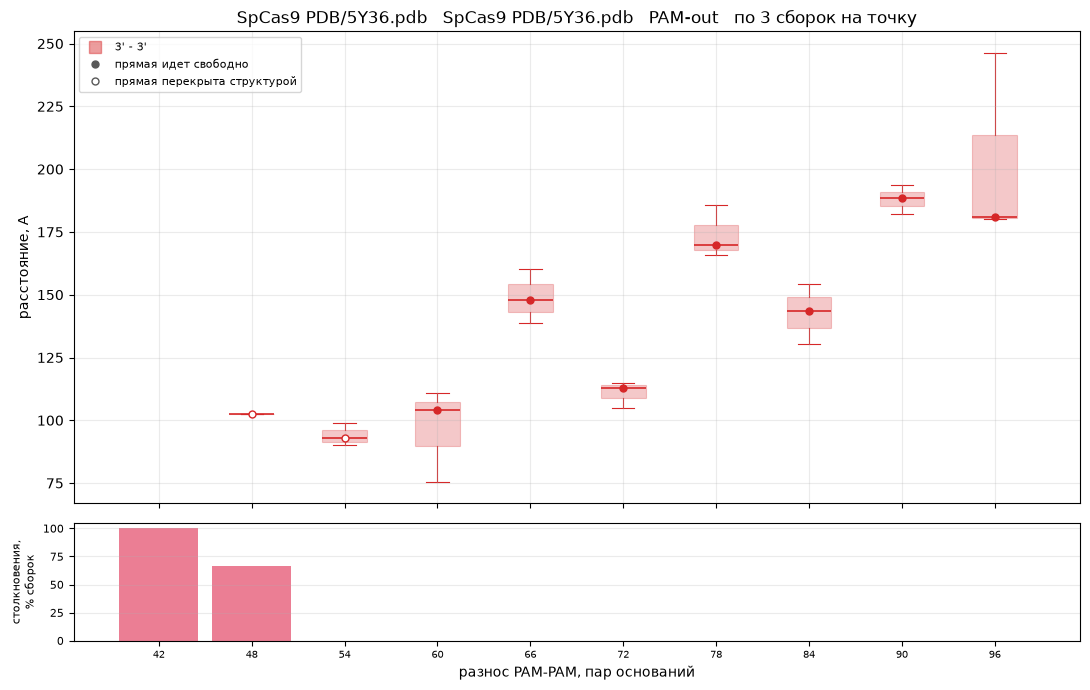

In [13]:
fig, stats = plot_dist('SpCas9', 'SpCas9', 'PDB/5Y36.pdb', 'PDB/5Y36.pdb',
                       2, range(42, 100, 6), params="3'", repeats=3)

`stats` отдаёт сырые данные — по каждой сборке отдельно, чтобы можно было считать своё.
Списки выровнены: i-й элемент везде относится к i-й сборке.

In [14]:
d = sorted(stats)[3]
record = stats[d]

clash = np.array(record['clashing'])
values = np.array(record["3'"]['values'])

print(f'разнос {d} п.н.:')
print(f'   сборок всего            {len(values)}')
print(f'   из них со столкновением {clash.sum()}')
print(f"   3'-3' по годным, A      {np.round(values[~clash], 1)}")

разнос 60 п.н.:
   сборок всего            3
   из них со столкновением 0
   3'-3' по годным, A      [110.8  75.6 104.2]


### Несколько параметров сразу

`params` принимает строку для одного или список для нескольких.
Внимание: `("3'")` — это **строка**, а не кортеж, для кортежа нужна запятая `("3'",)`.
Модуль понимает обе записи.

/Users/ler0_oy/Claude/Module_dCas9/.venv/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/ler0_oy/Claude/Module_dCas9/.venv/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/ler0_oy/Claude/Module_dCas9/.venv/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/ler0_oy/Claude/Module_dCas9/.venv/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/ler0_oy/Claude/Module_dCas9/.venv/lib/python3.12/site-packages/MDAnalysis/coo

график сохранен: распределение.png


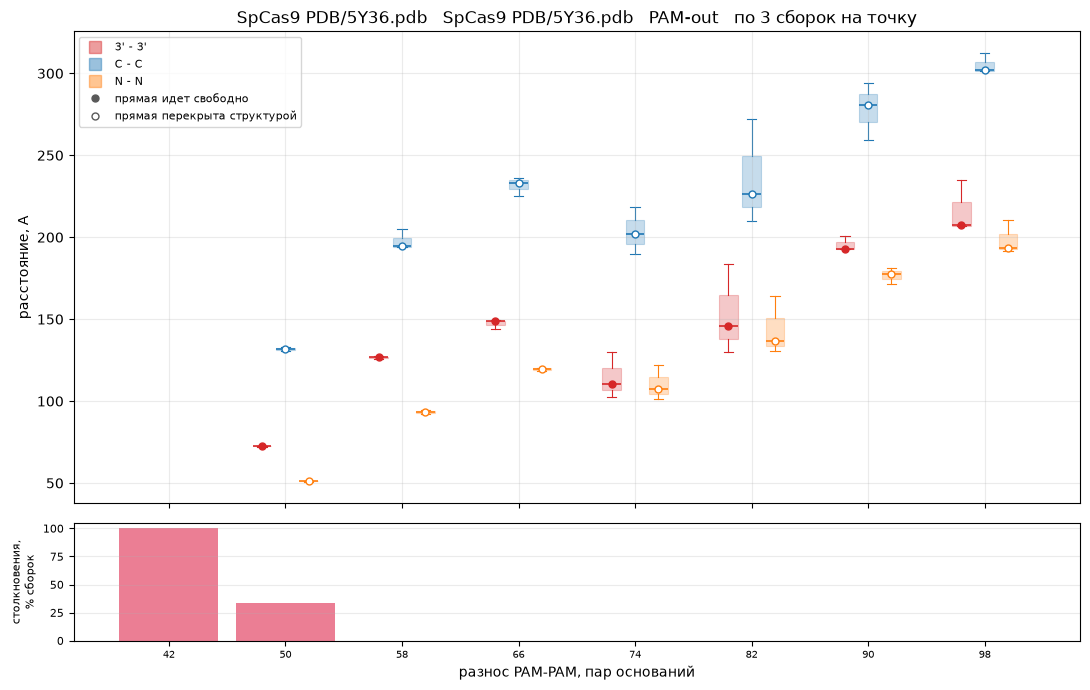

In [15]:
fig, stats = plot_dist('SpCas9', 'SpCas9', 'PDB/5Y36.pdb', 'PDB/5Y36.pdb',
                       2, range(42, 100, 8), params=["3'", 'C', 'N'], repeats=3,
                       save_png='распределение.png')

## Скорость

Сборка одной модели — около 0.5 с. Счёт идёт в несколько процессов, по числу ядер.

| | |
|---|---|
| `processes=None` | по числу ядер, по умолчанию |
| `processes=1` | без параллелизма, удобно при отладке |

На мелких заданиях параллелизм отключается сам: каждый процесс заново импортирует
MDAnalysis, и на коротком прогоне это не окупается.

Ориентир: 2000 сборок (20 разносов по 100 повторов) — около 4 минут.

## Сохранение моделей

Либо флагом `save=1` в `build_models` — тогда файлы лягут в `Cas_Cas_complex/<ориентация>/`,
либо вручную.

In [16]:
models[60].atoms.write('модель_PAM_out_60bp.pdb')
print('записано')

записано


## Воспроизводимость

По умолчанию конформер линкера и его положение выбираются случайно. Чтобы получить
ровно ту же модель, надо зафиксировать **оба** параметра.

In [17]:
one = build_models('SpCas9', 'SpCas9', 'PDB/5Y36.pdb', 'PDB/5Y36.pdb', 2, [60], 0,
                   DNA_name='0042', DNA_start=3)[60]
two = build_models('SpCas9', 'SpCas9', 'PDB/5Y36.pdb', 'PDB/5Y36.pdb', 2, [60], 0,
                   DNA_name='0042', DNA_start=3)[60]

print('RMSD двух прогонов:',
      round(float(np.sqrt(((one.atoms.positions - two.atoms.positions) ** 2).sum(1).mean())), 3), 'A')

RMSD двух прогонов: 0.0 A


## Справочник функций

**Сборка**

| функция | что делает |
|---|---|
| `build_models(...)` | собирает комплексы, главная функция |
| `prepare_structures(...)` | готовит структуры Cas: переименовывает цепи, режет ДНК по PAM |
| `prepare_DNA(dist, name, start)` | вытягивает линкерную ДНК из библиотеки |

**Проверки**

| функция | что делает |
|---|---|
| `check_model(model)` | полная диагностика, печатает где что не так |
| `check_clashing(model)` | сталкиваются ли белки |
| `how_many_atoms_clashing(model)` | сколько атомов в зоне контакта |
| `check_seams(model)` | разошлись ли швы сшивки |
| `backbone_bonds(model)` | все связи O3-P с номерами остатков |

**Расстояния**

| функция | что делает |
|---|---|
| `get_dist(models, param)` | расстояния по прямой |
| `check_dist_path(model, param)` | не идёт ли прямая сквозь структуру |
| `show_dist(model, param)` | показать расстояние в nglview |
| `dist_endpoints(model, param)` | координаты измеряемых точек |

**Статистика**

| функция | что делает |
|---|---|
| `plot_dist(...)` | собрать статистику и построить график |
| `collect_dist_stats(...)` | только собрать данные |
| `plot_dist_stats(stats, ...)` | только нарисовать по готовым данным |
| `plot_clashing(stats, ax)` | панель с долей столкновений |

## Что известно про ограничения

**Структуры.** Все три ориентации работают на 5Y36, 4UN3, 5CZZ, 5AXW, 6JDV, 6WBR, 6NY2 —
это SpCas9, SaCas9, Nme1Cas9, AcCas9 и CasX. На 5F9R, 7S4U, 6JE3 надёжно работает только
PAM-in; на 6O0Y и 7S4X сборка проходит, но швы расходятся. Причина общая: в кристаллах
нетаргетная цепь ДНК короче таргетной, и стыковка на таком дуплексе ещё не доведена.

Структура 4OO8 не подходит в принципе — в её ДНК нет PAM-сайта.

**Словарь PAM.** Записи `CasX` и `GoCas12` в `pam_seq` стоит сверить с литературой перед
работой: они не проверялись на структурах так же, как остальные ортологи. У CasX (6NY2)
цепи и PAM распознаются, но спаривание спейсера гРНК с протоспейсером не опознаётся,
и нумерация гРНК остаётся позиционной — модуль об этом предупреждает в выводе.

**Расстояние по прямой.** Обходной путь вокруг структуры пока не считается — есть только
пометка, что прямая перекрыта. Это следующая задача.

**Разброс.** Конформер ДНК случайный, и это не шум: изгиб спирали реально меняет расстояние,
иногда на десятки ангстрем. Поэтому статистику надо набирать повторами, а не одной сборкой.